In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import scipy as sc
from scipy import sparse
import warnings
from scipy.optimize import fsolve
from __future__ import annotations
from numba import njit, prange, set_num_threads
from scipy.signal import fftconvolve
warnings.filterwarnings('ignore')

# Define + register custom colormap early so it's available to all later plots
m_cols = plt.cm.magma(np.linspace(0, 1, 256))
p_cols = plt.cm.plasma(np.linspace(0, 1, 256))
plagma_cmap = LinearSegmentedColormap.from_list('plagma', 0.60 * m_cols + 0.40 * p_cols)
if 'plagma' not in plt.colormaps():
    plt.colormaps.register(plagma_cmap)

print("✓ All imports successful!")
print("✓ Custom colormap 'plagma' is defined and registered")

✓ All imports successful!
✓ Custom colormap 'plagma' is defined and registered


In [2]:
# Spatial parameters
d = 2  # dimension
N = 128 + 1  # grid points per dimension CHANGE BACK TO 32 BEFORE YOU RUN
dx = 2.0 / (N - 1)  # spatial step
x_grid = np.linspace(-1.0, 1.0, N)  # spatial grid maybe this should be changed too

# Temporal parameters
dt = 0.1  # time step
T = 90 # final time
time_steps = int(np.floor(T / dt)) + 1  # number of time steps

# Interaction parameters
beta = 0.5  # weighting parameter
R = 0.2  # interaction radius

# Initial opinion state
w_init = np.array([0.5, 0.5])  # initial w in [0,1]^d

print(f"Spatial domain: {d}D with N={N} points (dx={dx:.4f})")
print(f"Time domain: T={T} with dt={dt} (time_steps={time_steps})")
print(f"Initial opinion: w(0) = {w_init}")

Spatial domain: 2D with N=129 points (dx=0.0156)
Time domain: T=90 with dt=0.1 (time_steps=901)
Initial opinion: w(0) = [0.5 0.5]


In [3]:
xgrid_try = np.linspace(-1+dx/2, 1-dx/2, N)
# Define initial density
def initial_density(x):
    """Initial density in spatial domain only"""
    return 1.0  # uniform

# Create and normalize initial condition: shape (N^d,)
init_cond = np.array([initial_density(np.array([x1, x2])) 
                      for x1 in x_grid for x2 in x_grid])
init_cond = init_cond.reshape(N**d)

# Normalize to unit mass
initial_mass = np.sum(init_cond) * (dx**2)
init_cond /= initial_mass

print(f"Initial condition shape: {init_cond.shape}")
print(f"Initial mass (normalized): {np.sum(init_cond) * (dx**2):.6f}")

Initial condition shape: (16641,)
Initial mass (normalized): 1.000000


In [4]:
def kahan_sum(values):
    s = 0.0
    c = 0.0
    for v in values:
        y = v - c
        t = s + y
        c = (t - s) - y
        s = t
    return s

def variance(f_n):
    dA = dx ** 2

    X, Y = np.meshgrid(xgrid_try, xgrid_try, indexing='ij')

    # Flatten everything so both components use identical summation order
    F = f_n.ravel()
    Xf = X.ravel()
    Yf = Y.ravel()
    
    Ex = kahan_sum(Xf * F) * dA
    Ey = kahan_sum(Yf * F) * dA

    # Second moment using |x|^2
    RX = Xf**2 * F
    RY = Yf**2 * F
    mX = kahan_sum(RX) * dA
    mY = kahan_sum(RY) * dA

    Var = mX + mY - (Ex**2 + Ey**2)

    return Var, [Ex, Ey]


In [5]:
@njit(inline="always", cache=True)
def _q(s):
    den = s * s + (1 - s) * (1 - s)
    return s * s / den


@njit(inline="always", cache=True)
def _phi(delta0, delta1, w0, beta, r1, r2, component):
    a0 = abs(delta0)
    a1 = abs(delta1)
    weighted = w0 * a0 + (1 - w0) * a1
    p = (
        beta * a0 + (1 - beta) * weighted
        if component == 0
        else beta * a1 + (1 - beta) * weighted
    )
    if p < r1:
        return 1.0
    if p >= r2:
        return 0.0
    return _q((r2 - p) / (r2 - r1))


@njit(inline="always", cache=True)
def _rad(length, dx, N):
    if not np.isfinite(length):
        return N
    return max(0, min(int(length / dx), N))

In [6]:
@njit(cache=True)
def _tight(N, dx, r2, beta, w0, r1):
    om = 1 - beta
    w1 = 1 - w0
    ds = (beta + om * w0, om * w1, om * w0, beta + om * w1)
    ls = np.empty(4)
    for z in range(4):
        ls[z] = np.inf if ds[z] <= 0 else r2 / ds[z]
    rs = np.empty(4, np.int64)
    for z in range(4):
        rs[z] = _rad(ls[z], dx, N)

    r11, r12, r21, r22 = rs
    s0 = np.empty((2 * r11 + 1, 2 * r12 + 1))
    s1 = np.empty((2 * r21 + 1, 2 * r22 + 1))
    for a in range(s0.shape[0]):
        for b in range(s0.shape[1]):
            s0[a, b] = _phi(
                (a - r11) * dx, (b - r12) * dx, w0, beta, r1, r2, 0
            )
    for a in range(s1.shape[0]):
        for b in range(s1.shape[1]):
            s1[a, b] = _phi(
                (a - r21) * dx, (b - r22) * dx, w0, beta, r1, r2, 1
            )
    return s0, s1, np.array([[r11, r12], [r21, r22]])


def tight_rectangle(N, r1, r2, beta, w0, dx=None):
    """Construct the same compact interaction rectangles as the direct solver."""
    if dx is None:
        dx = 2 / (N - 1)
    if not (0 <= w0 <= 1):
        raise ValueError("w0 must lie in [0, 1].")
    if not (0 <= r1 < r2):
        raise ValueError("Require 0 <= r1 < r2.")
    a, b, rho = _tight(N, dx, r2, beta, w0, r1)
    return [a, b], rho


In [7]:
@njit(cache=True)
def _transport_kernels(shape, rho0, rho1, dx, w0, beta, r1, r2, direction):
    """Build phi*displacement and its constrained w0 derivative."""
    h = np.empty_like(shape)
    dh = np.empty_like(shape)
    for a in range(shape.shape[0]):
        d0 = (a - rho0) * dx
        for b in range(shape.shape[1]):
            d1 = (b - rho1) * dx
            disp = d0 if direction == 0 else d1
            h[a, b] = shape[a, b] * disp

            a0 = abs(d0)
            a1 = abs(d1)
            weighted = w0 * a0 + (1 - w0) * a1
            p = (
                beta * a0 + (1 - beta) * weighted
                if direction == 0
                else beta * a1 + (1 - beta) * weighted
            )
            dpdw = (1 - beta) * (a0 - a1)
            dphi = 0.0
            if r1 <= p < r2:
                s = (r2 - p) / (r2 - r1)
                den = s * s + (1 - s) * (1 - s)
                qprime = 2 * s * (1 - s) / (den * den)
                dphi = -qprime * dpdw / (r2 - r1)
            dh[a, b] = dphi * disp
    return h, dh


@njit(parallel=True, fastmath=True, cache=True)
def _corr_direct(a, h, r0, r1):
    """Zero-padded correlation used for forward velocities."""
    N = a.shape[0]
    out = np.empty_like(a)
    for p in prange(N * N):
        i = p // N
        j = p - i * N
        total = 0.0
        for u in range(max(0, i - r0), min(N - 1, i + r0) + 1):
            hu = u - i + r0
            for v in range(max(0, j - r1), min(N - 1, j + r1) + 1):
                total += h[hu, v - j + r1] * a[u, v]
        out[i, j] = total
    return out

In [8]:
@njit(parallel=True, fastmath=True, cache=True)
def _conv_direct(a, h, r0, r1):
    """Transpose of _corr_direct."""
    N = a.shape[0]
    out = np.empty_like(a)
    for p in prange(N * N):
        i = p // N
        j = p - i * N
        total = 0.0
        for u in range(max(0, i - r0), min(N - 1, i + r0) + 1):
            hu = i - u + r0
            for v in range(max(0, j - r1), min(N - 1, j + r1) + 1):
                total += h[hu, j - v + r1] * a[u, v]
        out[i, j] = total
    return out


def _apply(a, h, r0, r1, transpose=False, backend="auto", direct_limit=1024):
    """Use Numba for small supports and FFT convolution for large supports."""
    use_fft = backend == "fft" or (backend == "auto" and h.size > direct_limit)
    if use_fft:
        kernel = h if transpose else h[::-1, ::-1]
        return fftconvolve(a, kernel, mode="same")
    if backend not in ("auto", "direct"):
        raise ValueError("backend must be 'auto', 'direct', or 'fft'.")
    if transpose:
        return _conv_direct(a, h, r0, r1)
    return _corr_direct(a, h, r0, r1)


@njit(inline="always", cache=True)
def _pivot(x):
    if abs(x) < 1e-15:
        return 1e-15 if x >= 0 else -1e-15
    return x


In [9]:
@njit(parallel=True, fastmath=True, cache=True)
def _solve_lines(f, up, um, c, N, direction, transpose):
    """Parallel Thomas solves for A or A.T along independent grid lines."""
    out = np.empty_like(f)
    for line in prange(N):
        cp = np.empty(N)
        dp = np.empty(N)
        for n in range(N):
            p = n * N + line if direction == 0 else line * N + n
            diag = 1 + c * (up[p] - um[p])
            if not transpose:
                lower = (
                    -c * up[p - N if direction == 0 else p - 1]
                    if n > 0
                    else 0.0
                )
                upper = (
                    c * um[p + N if direction == 0 else p + 1]
                    if n < N - 1
                    else 0.0
                )
            else:
                lower = c * um[p] if n > 0 else 0.0
                upper = -c * up[p] if n < N - 1 else 0.0

            if n == 0:
                piv = _pivot(diag)
                cp[n] = upper / piv if N > 1 else 0.0
                dp[n] = f[p] / piv
            else:
                piv = _pivot(diag - lower * cp[n - 1])
                cp[n] = upper / piv if n < N - 1 else 0.0
                dp[n] = (f[p] - lower * dp[n - 1]) / piv

        p = (N - 1) * N + line if direction == 0 else line * N + N - 1
        out[p] = dp[N - 1]
        for n in range(N - 2, -1, -1):
            p = n * N + line if direction == 0 else line * N + n
            pn = p + N if direction == 0 else p + 1
            out[p] = dp[n] - cp[n] * out[pn]
    return out


def _stage_data(f, w0, dx, N, direction, beta, r1, r2, backend, direct_limit):
    shapes, rho = tight_rectangle(N, r1, r2, beta, w0, dx)
    r0, r1i = map(int, rho[direction])
    h, dh = _transport_kernels(
        np.ascontiguousarray(shapes[direction]),
        r0,
        r1i,
        dx,
        w0,
        beta,
        r1,
        r2,
        direction,
    )
    u = dx * dx * _apply(
        f.reshape(N, N), h, r0, r1i, False, backend, direct_limit
    )
    return h, dh, r0, r1i, u.ravel()


def _stage(f, w0, dt_stage, dx, N, direction, beta, r1, r2, backend, direct_limit):
    h, dh, r0, r1i, u = _stage_data(
        f, w0, dx, N, direction, beta, r1, r2, backend, direct_limit
    )
    up = np.maximum(u, 0)
    um = np.minimum(u, 0)
    y = _solve_lines(f, up, um, dt_stage / dx, N, direction, False)
    return y, (h, dh, r0, r1i, u, up, um)

In [10]:
@njit(parallel=True, fastmath=True, cache=True)
def _velocity_residual_multiplier(z, y, u, c, N, direction):
    """Derivative of z.T(A(u)y) with respect to each cell velocity."""
    g = np.empty_like(u)
    for p in prange(N * N):
        n = p // N if direction == 0 else p % N
        if u[p] > 0:
            z_next = (
                z[p + N]              
                if direction == 0 and n < N - 1
                else (z[p + 1] if direction == 1 and n < N - 1 else 0.0)
            )
            g[p] = c * y[p] * (z[p] - z_next)
        elif u[p] < 0:
            z_prev = (
                z[p - N]
                if direction == 0 and n > 0
                else (z[p - 1] if direction == 1 and n > 0 else 0.0)
            )
            g[p] = c * y[p] * (z_prev - z[p])
        else:
            g[p] = 0.0
    return g


def _reverse_stage(
    lam, y, f_in, data, dt_stage, dx, N, direction, backend, direct_limit
):
    h, dh, r0, r1i, u, up, um = data

    z = _solve_lines(lam, up, um, dt_stage / dx, N, direction, True)
    gu = _velocity_residual_multiplier(z, y, u, dt_stage / dx, N, direction)

    interaction_t = dx * dx * _apply(
        gu.reshape(N, N), h, r0, r1i, True, backend, direct_limit
    )
    lambda_in = z - interaction_t.ravel()

    du_dw0 = dx * dx * _apply(
        f_in.reshape(N, N), dh, r0, r1i, False, backend, direct_limit
    )
    grad_w0 = -np.dot(gu, du_dw0.ravel())
    return lambda_in, grad_w0, z


@njit(cache=True)
def _weight_update(w, control, dt, d):
    den = 1 + (dt / d) * np.sum(control)
    out = (w + (dt / d) * control) / den
    for a in range(d):
        out[a] = min(1.0, max(0.0, out[a]))
    return out

In [11]:
def _control_at(control, k, d):
    c = np.asarray(control, dtype=np.float64)
    if c.ndim == 1:
        if c.size != d:
            raise ValueError("A constant control must have shape (d,).")
        return c
    if c.ndim == 2 and c.shape[0] == d:
        return c[:, k]
    raise ValueError("Control must have shape (d,) or (d, nt-1).")

In [12]:
def solve_pde_with_w(
    init_f,
    init_w,
    I_control,
    dt,
    dx,
    time_steps,
    N,
    d,
    x_grid,
    beta,
    r1,
    r2,
    *,
    num_threads=None,
    backend="auto",
    direct_limit=1024,
    progress=False,
    return_cache=False,
):
    """
    Hybrid Numba/FFT forward solver.

    With return_cache=False, returns the original three arrays
    (f_all, w_all, fhalf_all). With return_cache=True, it additionally returns
    stage data that lets solve_adjoint avoid recomputing all velocities.
    """
    if d != 2:
        raise NotImplementedError("This implementation supports d=2 only.")
    if num_threads is not None:
        set_num_threads(int(num_threads))

    f0 = np.asarray(init_f, dtype=np.float64).reshape(-1)
    w0 = np.asarray(init_w, dtype=np.float64).reshape(-1)
    x_grid = np.asarray(x_grid, dtype=np.float64)
    if f0.size != N * N or w0.size != 2 or x_grid.size != N:
        raise ValueError("Invalid initial-state or grid shape.")
    if N > 1 and not np.allclose(np.diff(x_grid), dx):
        raise ValueError("x_grid must be uniform with spacing dx.")

    f_all = np.empty((N * N, time_steps))
    w_all = np.empty((2, time_steps))
    fhalf_all = np.empty((N * N, max(0, time_steps - 1)))
    f_all[:, 0] = f0
    w_all[:, 0] = w0
    cache = []
    dt_stage = 0.5 * dt

    for k in range(time_steps - 1):
        control = _control_at(I_control, k, 2)
        f_half, x_data = _stage(
            f_all[:, k],
            w_all[0, k],
            dt_stage,
            dx,
            N,
            0,
            beta,
            r1,
            r2,
            backend,
            direct_limit,
        )
        f_next, y_data = _stage(
            f_half,
            w_all[0, k],
            dt_stage,
            dx,
            N,
            1,
            beta,
            r1,
            r2,
            backend,
            direct_limit,
        )
        fhalf_all[:, k] = f_half
        f_all[:, k + 1] = f_next
        w_all[:, k + 1] = _weight_update(w_all[:, k], control, dt, 2)
        if return_cache:
            cache.append((x_data, y_data))
        if progress and (k + 1) % max(1, (time_steps - 1) // 5) == 0:
            print(f"step {k + 1}/{time_steps - 1}")

    if return_cache:
        return f_all, w_all, fhalf_all, cache
    return f_all, w_all, fhalf_all


In [13]:
def variance_squared_cost_gradient(f, x_grid, dx, dt, T, variance_desired):
    """Euclidean gradient of dt/(4T)*(V-V_des)^2 for unit-mass f."""
    N = len(x_grid)
    X0, X1 = np.meshgrid(x_grid, x_grid, indexing="ij")
    ff = np.asarray(f).reshape(N, N)
    mass_weight = dx * dx
    mean0 = mass_weight * np.sum(X0 * ff)
    mean1 = mass_weight * np.sum(X1 * ff)
    radius2 = (X0 - mean0) ** 2 + (X1 - mean1) ** 2
    variance = mass_weight * np.sum(radius2 * ff)
    return (
        dt
        * mass_weight
        / ( T)
        * (variance - variance_desired)
        * radius2
    ).ravel()

In [14]:
def solve_adjoint(
    f_all,
    w_all,
    I_control,
    dt,
    dx,
    x_grid,
    beta,
    r1,
    r2,
    variance_desired,
    T=None,
    half_states=None,
    *,
    terminal_f=None,
    terminal_w=None,
    objective_gradient=None,
    forward_cache=None,
    num_threads=None,
    backend="auto",
    direct_limit=1024,
):
    """
    Scalable exact reverse mode of solve_pde_with_w.

    This is differentiable away from zero-velocity upwind switches and active
    clipping bounds. If supplied, objective_gradient is called as
    objective_gradient(f_at_kplus1, k+1) and must return an ordinary Euclidean
    derivative with respect to the flattened density.
    """
    if num_threads is not None:
        set_num_threads(int(num_threads))
    f_all = np.ascontiguousarray(f_all, dtype=np.float64)
    w_all = np.ascontiguousarray(w_all, dtype=np.float64)
    x_grid = np.asarray(x_grid, dtype=np.float64)
    N = len(x_grid)
    nt = f_all.shape[1]
    M = N * N
    if f_all.shape != (M, nt) or w_all.shape != (2, nt):
        raise ValueError("Expected f_all=(N**2, nt) and w_all=(2, nt).")
    if T is None:
        T = dt * max(nt - 1, 1)

    if half_states is None:
        half = np.empty((M, max(0, nt - 1)))
        for k in range(nt - 1):
            half[:, k], _ = _stage(
                f_all[:, k],
                w_all[0, k],
                0.5 * dt,
                dx,
                N,
                0,
                beta,
                r1,
                r2,
                backend,
                direct_limit,
            )
    else:
        half = np.ascontiguousarray(half_states, dtype=np.float64)

    bar_f = np.zeros_like(f_all)
    bar_w = np.zeros_like(w_all)
    if terminal_f is not None:
        bar_f[:, -1] = terminal_f
    if terminal_w is not None:
        bar_w[:, -1] = terminal_w

    dt_stage = 0.5 * dt
    for k in range(nt - 2, -1, -1):
        f0 = f_all[:, k]
        f_half = half[:, k]
        f1 = f_all[:, k + 1]
        w0 = w_all[0, k]

        if forward_cache is None:
            hx, dhx, rx0, rx1, ux = _stage_data(
                f0, w0, dx, N, 0, beta, r1, r2, backend, direct_limit
            )
            hy, dhy, ry0, ry1, uy = _stage_data(
                f_half, w0, dx, N, 1, beta, r1, r2, backend, direct_limit
            )
            x_data = (
                hx,
                dhx,
                rx0,
                rx1,
                ux,
                np.maximum(ux, 0.0),
                np.minimum(ux, 0.0),
            )
            y_data = (
                hy,
                dhy,
                ry0,
                ry1,
                uy,
                np.maximum(uy, 0.0),
                np.minimum(uy, 0.0),
            )
        else:
            x_data, y_data = forward_cache[k]

        forcing = variance_squared_cost_gradient(
            f1, x_grid, dx, dt, T, variance_desired
        )

        adj_half, grad_w_y, _ = _reverse_stage(
            bar_f[:, k + 1] + forcing,
            f1,
            f_half,
            y_data,
            dt_stage,
            dx,
            N,
            1,
            backend,
            direct_limit,
        )
        bar_f[:, k], grad_w_x, _ = _reverse_stage(
            adj_half,
            f_half,
            f0,
            x_data,
            dt_stage,
            dx,
            N,
            0,
            backend,
            direct_limit,
        )

        control = _control_at(I_control, k, 2)
        denominator = 1 + 0.5 * dt * np.sum(control)
        bar_w[:, k] = bar_w[:, k + 1] / denominator

        # The computational forward map calls tight_rectangle with w[0] and
        # sets the second kernel weight to 1-w[0]. Thus its direct PDE
        # derivative is represented by the first adjoint component.
        bar_w[0, k] += grad_w_x + grad_w_y

    return bar_f, bar_w

def warm_up(N, dx, beta, r1, r2, num_threads=None):
    """Compile Numba kernels before benchmarking a real simulation."""
    if num_threads is not None:
        set_num_threads(int(num_threads))
    f = np.ones(N * N)
    f /= np.sum(f) * dx * dx
    y, data = _stage(
        f, 0.5, 0.05, dx, N, 0, beta, r1, r2, "direct", 10**9
    )
    _reverse_stage(
        np.ones_like(f), y, f, data, 0.05, dx, N, 0, "direct", 10**9
    )
    _weight_update(np.array([0.5, 0.5]), np.array([0.5, 0.5]), 0.1, 2)

In [15]:
def instantaneous_objective(I_t, f_all, w_all, dt, dx, N, d, xgrid, T, nu, V_des):
    """One-step reduced objective from current state with control I_t."""
    X0, X1 = np.meshgrid(x_grid, x_grid, indexing="ij")
    mass_weight = dx * dx
    V_all = np.zeros(K+1)
    
    for k in range(K+1):
        ff = np.asarray(f_all[:,k]).reshape(N, N)
        mean0 = mass_weight * np.sum(X0 * ff)
        mean1 = mass_weight * np.sum(X1 * ff)
        radius2 = (X0 - mean0) ** 2 + (X1 - mean1) ** 2
        variance = mass_weight * np.sum(radius2 * ff)
        V_all[k] = variance.copy()
        
    J_track = (dt / (4*(T))) * np.sum((V_all - V_des)**2)
    J_ctrl = ( nu*K*dt / (2*d)) * np.sum(I_t**2)
    return J_track + J_ctrl

def instantaneous_gradient_adjoint(I_t, f_all, fhalf_all, w_all, dt, dx, N, d, xgrid, T, nu, V_des):
    """Theoretical reduced gradient for one time slice using adjoint variables."""
    
    fbar_all, wbar_all = solve_adjoint(f_all, w_all, I_t, dt, dx, x_grid, beta, r1, r2, V_des, T, fhalf_all, terminal_f=None, terminal_w=None, objective_gradient=None, forward_cache=None, num_threads=None, backend="auto", direct_limit=1024)

    grad_integrand = np.zeros(d)

    for t in range(K+1):
        wbar_t = wbar_all[:, t]
        scalar_w_wbar = float(np.dot(w_all[:,t], wbar_t))
        grad_integrand += dt*((1.0 / (d)) * (wbar_t - np.ones(d) * scalar_w_wbar) + (nu / d) * I_t) / ((K+1)*dt)

        
    return grad_integrand

In [16]:
def project_control(I):
    """Project control vector or matrix to [0,1]."""
    return np.clip(I, 0.0, 1.0)

def armijo_projected_step(I_current, qk, f_all, w_all, fhalf_all, dt, dx, N, d, xgrid, T, nu, V_des,
                          omega0=1000, gamma=1e-4, max_backtrack=8):
    """Projected Armijo line search for one-slice reduced objective."""
    f_cur = f_all[:,0].copy()
    w_cur = w_all[:,0].copy()
    J_current = instantaneous_objective(
        I_current, f_all, w_all, dt, dx, N, d, xgrid, T, nu, V_des
    )

    grad_norm_sq = float(np.dot(qk, qk))
    omega = float(omega0)

    I_trial = project_control(I_current - omega * qk)
    if np.array_equal(I_current, I_trial):
        return I_trial, J_current, f_all, w_all, fhalf_all

    f_trial, w_trial, fhalf_trial = solve_pde_with_w(f_cur, w_cur, I_trial, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
    J_trial = instantaneous_objective(
        I_trial, f_trial, w_trial, dt, dx, N, d, xgrid, T, nu, V_des
    )


    backtracks = 0
    armijobacktracks = 0
    goldsteinbacktracks = 0

    
    while J_trial >= J_current - gamma * omega * grad_norm_sq and backtracks < max_backtrack:
        omega /= 2
        I_trial = project_control(I_current - omega * qk)
        f_trial, w_trial, fhalf_trial = solve_pde_with_w(f_cur, w_cur, I_trial, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
        J_trial = instantaneous_objective(
            I_trial, f_trial, w_trial, dt, dx, N, d, xgrid, T, nu, V_des
        )
        backtracks += 1
        armijobacktracks += 1

    while J_trial < J_current - (1-gamma) * omega * grad_norm_sq and backtracks < max_backtrack: # choose goldstein coefficient as 1-gamma with gamma from armijo condition
        omega *= 2
        I_trial = project_control(I_current - omega * qk)
        f_trial, w_trial, fhalf_trial = solve_pde_with_w(f_cur, w_cur, I_trial, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
        J_trial = instantaneous_objective(
            I_trial, f_trial, w_trial, dt, dx, N, d, xgrid, T, nu, V_des
        )
        backtracks += 1
        goldsteinbacktracks += 1


    if J_trial > J_current:
        
        return I_current, J_current, f_all, w_all, fhalf_all
    
    return I_trial, J_trial, f_trial, w_trial, fhalf_trial


def long_gradient_descent(I_current, qk, f_all, fhalf_all, w_all, dt, dx, N, d, xgrid, T, nu, V_des):
    # this means calculating a lot more adjoint things
    J_current = 10**4
    max_iters = 100
    iters = 0
    f_cur = f_all[:,0].copy()
    w_cur = w_all[:,0].copy()
    I_trial, J_trial, f_trial, w_trial, fhalf_trial = armijo_projected_step(I_current, qk, f_all, w_all, fhalf_all, dt, dx, N, d, xgrid, T, nu, V_des, omega0=1000, gamma=1e-4, max_backtrack=8)
    if np.array_equal(I_current, I_trial):
        return I_current, J_trial, f_all, w_all, fhalf_all
    while np.abs(J_current - J_trial)/abs(J_trial)>10**(-8) and iters < max_iters:
        J_current = np.copy(J_trial)
        I_current = np.copy(I_trial)

        f_current, w_current, fhalf_current = solve_pde_with_w(f_cur, w_cur, I_current, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
        qk = instantaneous_gradient_adjoint(I_current, f_current, fhalf_current, w_current, dt, dx, N, d, x_grid, (K+1)*dt, nu_opt, V_des)
        
        I_trial, J_trial, f_trial, w_trial, fhalf_trial = armijo_projected_step(I_current, qk, f_current, w_current, fhalf_current, dt, dx, N, d, xgrid, T, nu, V_des, omega0=1000, gamma=1e-4, max_backtrack=8)
        iters += 1
    return I_trial, J_trial, f_trial, w_trial, fhalf_trial
    

In [17]:
def find_variance(f, x_grid):
    X0, X1 = np.meshgrid(x_grid, x_grid, indexing="ij")
    mass_weight = dx * dx
    ff = np.asarray(f).reshape(N, N)
    mean0 = mass_weight * np.sum(X0 * ff)
    mean1 = mass_weight * np.sum(X1 * ff)
    radius2 = (X0 - mean0) ** 2 + (X1 - mean1) ** 2
    variance = mass_weight * np.sum(radius2 * ff)
    return variance

In [18]:
# Instantaneous control optimization parameters (Algorithm 1 style)
V_des =0.0
nu_opt = 0.0

r1 = 0.1
r2 = 0.4

K = 20

T = 180
time_steps = int(np.floor(T / dt)) + 1 

# Allocate trajectory/control storage

I_init = np.zeros((d, time_steps))
I_opt = np.zeros((d, time_steps))
f_opt = np.zeros((N**d, time_steps))
grad1 = np.zeros((d, time_steps))
w_opt = np.zeros((d, time_steps))
J_all = np.zeros(time_steps)
stage_cost_hist = []

f_opt[:, 0] = init_cond
w_opt[:, 0] = w_init
I_init[:, 0] = [1, 0]


# Baseline (pre-optimization) variance from the untouched initial condition
V0_baseline = find_variance(init_cond, x_grid)

print("Starting INSTANTANEOUS projected-gradient optimization:")

from tqdm import tqdm

for t in tqdm(range(time_steps - 1)):
    f_cur = f_opt[:, t].copy()
    w_cur = w_opt[:, t].copy()
    c_k1 = I_init[:, t].copy()

    # 3-5) projected Armijo step + steepest descent update + projection
    
    f_all, w_all, fhalf_all = solve_pde_with_w(f_cur, w_cur, c_k1, dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)
    qk1 = instantaneous_gradient_adjoint(c_k1, f_all, fhalf_all, w_all, dt, dx, N, d, x_grid, K*dt, nu_opt, V_des)

    I_optimal, J_opt, f_optimal, w_optimal, fhalf_optimal = long_gradient_descent(c_k1, qk1, f_all, fhalf_all, w_all, dt, dx, N, d, x_grid, T, nu_opt, V_des)

    f_next = f_optimal[:,1].copy()
    w_next = w_optimal[:,1].copy()

    # Apply updated control on current slice and advance state

    grad1[:,t] = np.copy(qk1)
    J_all[t] = np.copy(J_opt)
    f_opt[:,t+1] = np.copy(f_next)
    w_opt[:,t+1] = np.copy(w_next)
    I_opt[:,t] = np.copy(I_optimal)
    
    if t + 1 < time_steps - 1:
        I_init[:,t+1] = np.copy(I_opt[:,t])
        
    stage_cost_hist.append(J_opt)

#Set final control value for reporting convenience

cost_hist = stage_cost_hist

print(f"\n{'='*60}")
print("INSTANTANEOUS optimization complete!")

Starting INSTANTANEOUS projected-gradient optimization:


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1800/1800 [20:48<00:00,  1.44it/s]


INSTANTANEOUS optimization complete!


Computing forward solution for animation...
Using optimized trajectories from Section 12 (I_opt, f_opt, w_opt).
Animation will show 20 frames from t=0 to t=171.0
✓ Animation saved as 'density_evolutionN128.gif'

🎬 Displaying animation from saved GIF file:
✓ Animation created! Shows density/control animation with full importance-weight and variance trajectories.
Control mode: optimized (time-varying I_opt(t))
I_opt(0)=[1. 0.], I_opt(T)=[0. 0.]
V(0)=0.666545, V(T)=0.000000


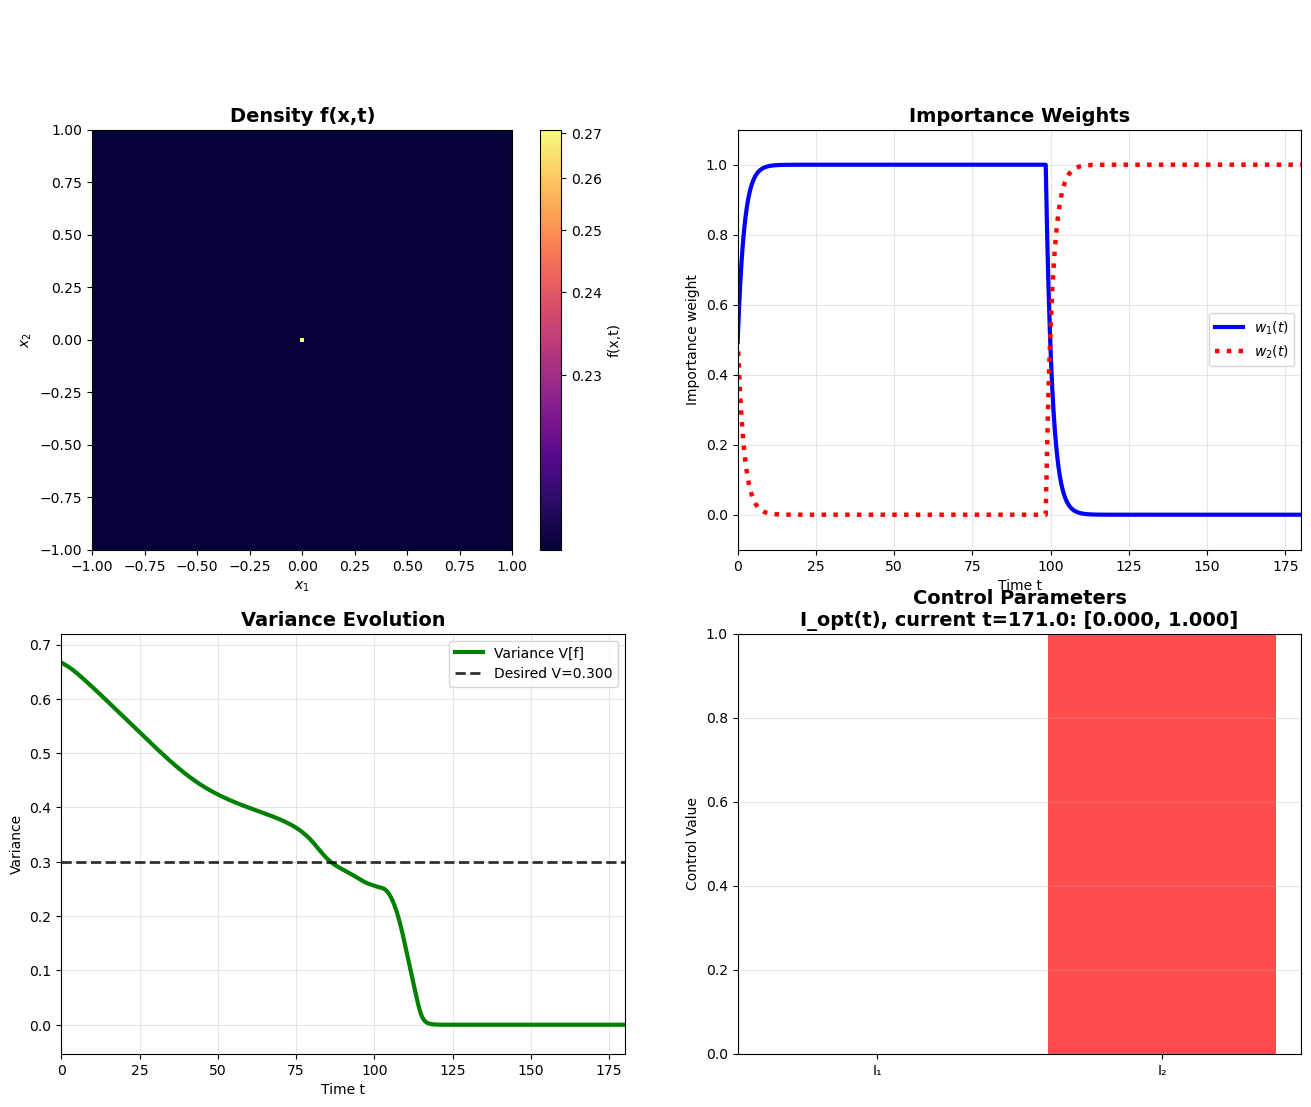

In [20]:
# Animation of forward solution evolution (uses optimized control by default)
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image
import matplotlib.colors as colors
import os

print("Computing forward solution for animation...")

f_shortened = f_opt[:,:1801]
w_shortened = w_opt[:,:1801]
I_shortened = I_opt[:,:1801]
J_shortened = J_all[:1801]

# Prefer optimized trajectories if available; otherwise fall back to constant demo control
if 'I_opt' in globals() and 'f_opt' in globals() and 'w_opt' in globals():
    I_anim = I_shortened
    f_anim = f_shortened
    w_anim = w_shortened
    control_mode = "optimized"
    print("Using optimized trajectories from Section 12 (I_opt, f_opt, w_opt).")
else:
    I_anim = np.array([0.5, 0.5])
    f_anim, w_anim = solve_pde_with_w(init_cond, w_init, I_anim, dt, dx, time_steps, N, d, x_grid)
    control_mode = "constant"
    print("Optimization outputs not found; using fallback constant control I = [0.5, 0.5].")

# Extract time snapshots (every few steps for smoother animation)
time_steps_shortened = 1801
anim_steps = min(20, time_steps_shortened)
step_size = max(1, time_steps_shortened // anim_steps)
time_indices = np.arange(0, time_steps_shortened, step_size)[:anim_steps]
time_vals = np.arange(time_steps_shortened) * dt
time_vals_anim = time_vals[time_indices]

print(f"Animation will show {len(time_indices)} frames from t=0 to t={time_vals_anim[-1]:.1f}")

# Set up the figure for animation
fig_anim, axes_anim = plt.subplots(2, 2, figsize=(16, 12))

# Top-left: 2D density heatmap
im_anim = axes_anim[0, 0].imshow(
    init_cond.reshape(N, N).T, extent=[-1, 1, -1, 1],
    origin='lower', cmap='plagma',  norm=colors.PowerNorm(gamma=0.5)
)
axes_anim[0, 0].set_title('Density f(x,t)', fontsize=14, fontweight='bold')
axes_anim[0, 0].set_xlabel('$x_1$')
axes_anim[0, 0].set_ylabel('$x_2$')
cbar = plt.colorbar(im_anim, ax=axes_anim[0, 0], label='f(x,t)')

# Top-right: full importance-weight trajectories (static)
axes_anim[0, 1].plot(time_vals, w_anim[0, :], 'b-', linewidth=3, label='$w_1(t)$')
axes_anim[0, 1].plot(time_vals, w_anim[1, :], 'r:', linewidth=3.2, label='$w_2(t)$')
axes_anim[0, 1].set_xlim(0, dt*time_steps_shortened)
axes_anim[0, 1].set_ylim(-0.1, 1.1)
axes_anim[0, 1].set_xlabel('Time t')
axes_anim[0, 1].set_ylabel('Importance weight')
axes_anim[0, 1].set_title('Importance Weights', fontsize=14, fontweight='bold')
axes_anim[0, 1].legend()
axes_anim[0, 1].grid(True, alpha=0.3)

# Bottom-left: Variance evolution
V_traj_anim = np.zeros(time_steps_shortened)
for t_idx in range(time_steps_shortened):
    V_traj_anim[t_idx], _ = variance(f_anim[:, t_idx])

V_des_plot = globals().get('V_des_opt', 0.3)
vmin = float(np.min(V_traj_anim))
vmax = float(np.max(V_traj_anim))
vspan = max(vmax - vmin, 1e-8)
vpad = 0.08 * vspan
ymin = min(vmin, V_des_plot) - vpad
ymax = max(vmax, V_des_plot) + vpad

axes_anim[1, 0].plot(time_vals, V_traj_anim, 'g-', linewidth=3, label='Variance V[f]')
axes_anim[1, 0].axhline(V_des_plot, color='k', linestyle='--', linewidth=2, alpha=0.8,
                        label=f'Desired V={V_des_plot:.3f}')
axes_anim[1, 0].set_xlim(0, dt*time_steps_shortened)
axes_anim[1, 0].set_ylim(ymin, ymax)
axes_anim[1, 0].set_xlabel('Time t')
axes_anim[1, 0].set_ylabel('Variance')
axes_anim[1, 0].set_title('Variance Evolution', fontsize=14, fontweight='bold')
axes_anim[1, 0].legend()
axes_anim[1, 0].grid(True, alpha=0.3)

# Bottom-right: Control values (dynamic if optimized)
if np.ndim(I_anim) == 2:
    I0 = I_anim[:, 0]
    control_title = f'Control Parameters\nI_opt(t), current t=0: [{I0[0]:.3f}, {I0[1]:.3f}]'
else:
    I0 = I_anim
    control_title = f'Control Parameters\nI = [{I0[0]:.3f}, {I0[1]:.3f}]'

bars = axes_anim[1, 1].bar(['I₁', 'I₂'], I0, color=['blue', 'red'], alpha=0.7)
axes_anim[1, 1].set_ylim(0, 1)
axes_anim[1, 1].set_ylabel('Control Value')
axes_anim[1, 1].set_title(control_title, fontsize=14, fontweight='bold')
axes_anim[1, 1].grid(True, alpha=0.3, axis='y')

# Time text
time_text = fig_anim.suptitle('Time: t = 0.0', fontsize=16, fontweight='bold')

def animate(frame_idx):
    t_idx = time_indices[frame_idx]
    t = time_vals_anim[frame_idx]

    # Update density heatmap
    f_2d = f_anim[:, t_idx].reshape(N, N).T
    im_anim.set_array(f_2d)

    # Update control bars and title
    if np.ndim(I_anim) == 2:
        I_now = I_anim[:, t_idx]
        bars[0].set_height(I_now[0])
        bars[1].set_height(I_now[1])
        axes_anim[1, 1].set_title(
            f'Control Parameters\nI_opt(t), current t={t:.1f}: [{I_now[0]:.3f}, {I_now[1]:.3f}]',
            fontsize=14, fontweight='bold'
)

    # Update time text
    time_text.set_text(f'Time: t = {t:.1f}')

    return [im_anim, time_text, bars[0], bars[1]]

# Create animation
anim = FuncAnimation(fig_anim, animate, frames=len(time_indices), interval=500, blit=True)

# Save animation as GIF
gif_filename = 'density_evolutionN128.gif'
try:
    anim.save(gif_filename, writer='pillow', fps=2, dpi=100)
    print(f"✓ Animation saved as '{gif_filename}'")
except Exception as e:
    print(f"Could not save GIF: {e}")

# Display animation
if os.path.exists(gif_filename):
    print("\n🎬 Displaying animation from saved GIF file:")
else:
    print("GIF file not found, trying alternative display methods...")
    try:
        print("Attempting HTML5 display...")
        display(HTML(anim.to_html5_video()))
    except:
        print("HTML5 video failed, trying JS animation...")
        try:
            display(HTML(anim.to_jshtml()))
        except Exception as e:
            print(f"All display methods failed: {e}")
            print("You can view the animation by opening 'density_evolution.gif' in an image viewer")

print("✓ Animation created! Shows density/control animation with full importance-weight and variance trajectories.")
if np.ndim(I_anim) == 2:
    print(f"Control mode: {control_mode} (time-varying I_opt(t))")
    print(f"I_opt(0)={I_anim[:,0]}, I_opt(T)={I_anim[:,-1]}")
else:
    print(f"Control mode: {control_mode} (constant I = {I_anim})")
print(f"V(0)={V_traj_anim[0]:.6f}, V(T)={V_traj_anim[-1]:.6f}")

Animation will show 40 frames from t=0 to t=175.5
✓ Animation saved as 'just_densityN126_nu0var0.gif'

🎬 Displaying animation from saved GIF file:


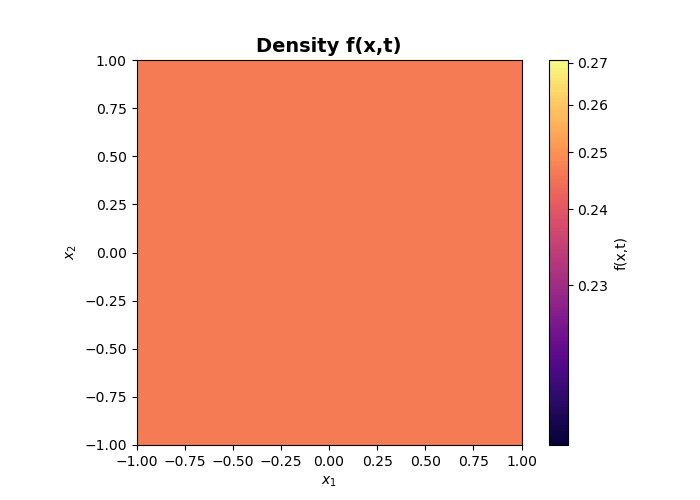

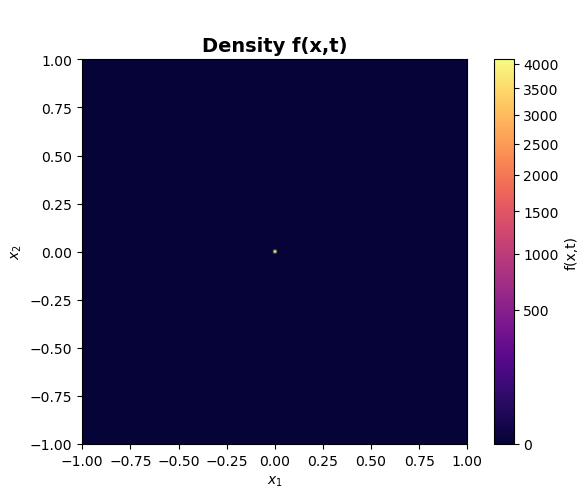

In [21]:
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image
import matplotlib.colors as colors
import os

# Extract time snapshots (every few steps for smoother animation)

time_steps_shortened = 1801
anim_steps = min(40, time_steps_shortened)
step_size = max(1, time_steps_shortened // anim_steps)
time_indices = np.arange(0, time_steps_shortened, step_size)[:anim_steps]
time_vals = np.arange(time_steps_shortened) * dt
time_vals_anim = time_vals[time_indices]

print(f"Animation will show {len(time_indices)} frames from t=0 to t={time_vals_anim[-1]:.1f}")

# Set up the figure for animation
fig_anim, axes_anim = plt.subplots(figsize=(7, 5))

# Top-left: 2D density heatmap
im_anim = axes_anim.imshow(
    init_cond.reshape(N, N).T, extent=[-1, 1, -1, 1],
    origin='lower', cmap='plagma',  norm=colors.PowerNorm(gamma=0.5)
)
axes_anim.set_title('Density f(x,t)', fontsize=14, fontweight='bold')
axes_anim.set_xlabel('$x_1$')
axes_anim.set_ylabel('$x_2$')
cbar = plt.colorbar(im_anim, ax=axes_anim, label='f(x,t)')


# Time text
time_text = fig_anim.suptitle('Time: t = 0.0', fontsize=16, fontweight='bold')

def animate(frame_idx):

    t_idx = time_indices[frame_idx]
    t = time_vals_anim[frame_idx]

    # Update density heatmap
    f_2d = f_anim[:, t_idx].reshape(N, N).T
    im_anim.set_array(f_2d)
    im_anim.set_clim(vmin = np.min(f_2d), vmax = np.max(f_2d))

    # Update time text
    time_text.set_text(f'Time: t = {t:.1f}')

    return [im_anim, time_text]

# Create animation
anim = FuncAnimation(fig_anim, animate, frames=len(time_indices), interval=500, blit=True)

# Save animation as GIF
gif_filename = 'just_densityN126_nu0var0.gif'
try:
    anim.save(gif_filename, writer='pillow', fps=4, dpi=100)
    print(f"✓ Animation saved as '{gif_filename}'")
except Exception as e:
    print(f"Could not save GIF: {e}")

# Display animation
if os.path.exists(gif_filename):
    print("\n🎬 Displaying animation from saved GIF file:")
    display(Image(filename=gif_filename))
else:
    print("GIF file not found, trying alternative display methods...")
    try:
        print("Attempting HTML5 display...")
        display(HTML(anim.to_html5_video()))
    except:
        print("HTML5 video failed, trying JS animation...")
        try:
            display(HTML(anim.to_jshtml()))
        except Exception as e:
            print(f"All display methods failed: {e}")
            print("You can view the animation by opening 'density_evolution.gif' in an image viewer")

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, PowerNorm, LogNorm
from matplotlib.gridspec import GridSpec


def plot_density_with_marginals(
    x1,
    x2,
    density,
    *,
    title=None,
    cmap="cividis",
    marginal_color="#0072B2",
    norm="power",
    gamma=0.35,
    vmin=None,
    vmax=None,
    ax=None,
    cax=None,
    ax_top=None,
    ax_right=None,
    figsize=(6.6, 5.6),
):
    """Plot a 2-D density together with its x1 and x2 marginal densities.

    Parameters
    ----------
    x1, x2 : 1-D arrays
        Coordinates of the density grid.
    density : 2-D array, shape (len(x2), len(x1))
        density[j, i] is the density at (x1[i], x2[j]).
    norm : {'linear', 'power', 'log'} or matplotlib.colors.Normalize
        'power' is usually best for narrow, Dirac-like spikes.
    gamma : float
        PowerNorm exponent. Values below 1 reveal lower-density structure.
    ax, cax, ax_top, ax_right : matplotlib axes, optional
        Supply all four axes to embed the plot in an existing figure.

    Returns
    -------
    fig, axes
        axes contains 'heatmap', 'colorbar', 'x1_marginal', and
        'x2_marginal'.
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)
    density = np.asarray(density)

    expected_shape = (x2.size, x1.size)
    if density.shape != expected_shape:
        raise ValueError(
            f"density must have shape {expected_shape}, but has {density.shape}. "
            "Transpose it if its axes are ordered as (x1, x2)."
        )
    if np.any(density < 0):
        raise ValueError("A probability density must be non-negative.")

    if any(a is None for a in (ax, cax, ax_top, ax_right)):
        fig = plt.figure(figsize=figsize, constrained_layout=True)
        gs = GridSpec(
            2,
            3,
            figure=fig,
            width_ratios=(0.07, 1.0, 0.30),
            height_ratios=(0.30, 1.0),
            wspace=0.06,
            hspace=0.06,
        )
        cax = fig.add_subplot(gs[1, 0])
        ax_top = fig.add_subplot(gs[0, 1])
        ax = fig.add_subplot(gs[1, 1], sharex=ax_top)
        ax_right = fig.add_subplot(gs[1, 2], sharey=ax)
    else:
        fig = ax.figure

    positive = density[density > 0]
    data_max = float(np.max(density))
    vmax = data_max if vmax is None else vmax

    if isinstance(norm, str):
        if norm == "linear":
            vmin = 0.0 if vmin is None else vmin
            colour_norm = Normalize(vmin=vmin, vmax=vmax)
        elif norm == "power":
            vmin = 0.0 if vmin is None else vmin
            colour_norm = PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)
        elif norm == "log":
            if positive.size == 0:
                raise ValueError("Log normalization requires positive density values.")
            vmin = float(np.min(positive)) if vmin is None else vmin
            colour_norm = LogNorm(vmin=vmin, vmax=vmax)
        else:
            raise ValueError("norm must be 'linear', 'power', 'log', or a Normalize object.")
    else:
        colour_norm = norm

    # x1 marginal: integrate over x2. x2 marginal: integrate over x1.
    marginal_x1 = np.trapz(density, x=x2, axis=0)
    marginal_x2 = np.trapz(density, x=x1, axis=1)

    mesh = ax.pcolormesh(
        x1,
        x2,
        density,
        shading="auto",
        cmap=cmap,
        norm=colour_norm,
        rasterized=True,
    )

    cb = fig.colorbar(mesh, cax=cax, orientation="vertical", ticklocation="left")
    cb.set_label(r"Density $f(x_1,x_2)$", labelpad=8)

    ax_top.plot(x1, marginal_x1, color=marginal_color, linewidth=1.8)
    ax_top.fill_between(x1, 0, marginal_x1, color=marginal_color, alpha=0.25)

    ax_right.plot(marginal_x2, x2, color=marginal_color, linewidth=1.8)
    ax_right.fill_betweenx(x2, 0, marginal_x2, color=marginal_color, alpha=0.25)

    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax_top.set_ylabel(r"$\int f\,dx_2$")
    ax_right.set_xlabel(r"$\int f\,dx_1$")

    ax_top.tick_params(axis="x", labelbottom=False)
    ax_right.tick_params(axis="y", labelleft=False)
    ax_top.spines[["top", "right"]].set_visible(False)
    ax_right.spines[["top", "right"]].set_visible(False)
    ax.set_box_aspect(1)

    ax_top.set_ylim(bottom=0)
    ax_right.set_xlim(left=0)
    ax.margins(x=0, y=0)

    if title:
        ax_top.set_title(title, pad=8)

    return fig, {
        "heatmap": ax,
        "colorbar": cax,
        "x1_marginal": ax_top,
        "x2_marginal": ax_right,
        "mappable": mesh,
        "colorbar_object": cb,
    }


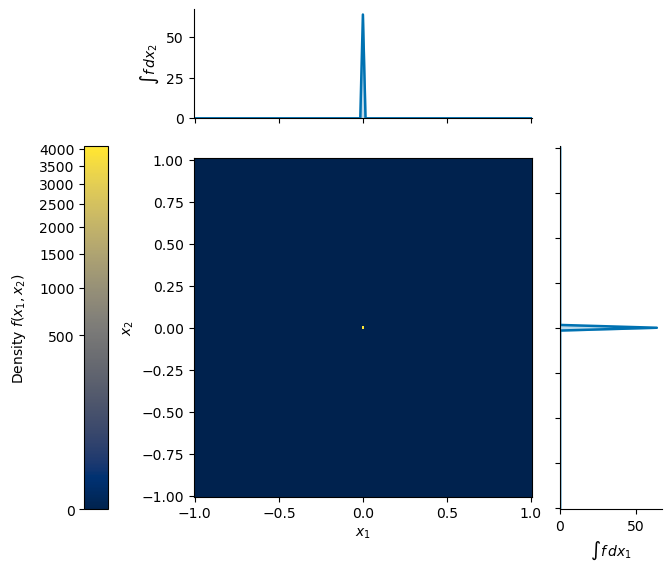

In [24]:
fig, axes = plot_density_with_marginals(x_grid,x_grid,f_opt[:,-1].reshape(N,N).T,title=None,cmap="cividis",marginal_color="#0072B2",norm="power",gamma=0.35,vmin=None,vmax=None,ax=None,cax=None,ax_top=None,ax_right=None,figsize=(6.6, 5.6))
#plt.tight_layout()
plt.savefig('density_with_marginals_uncontrolled_t180.pdf')
plt.show()

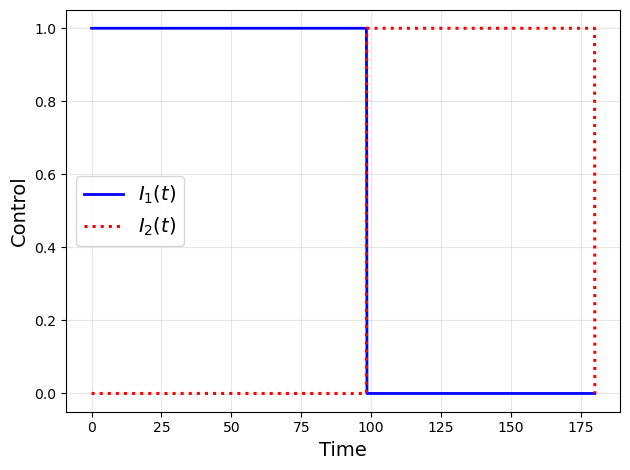

In [25]:
plt.plot(time_vals[:1801], I_shortened[0,:], 'b-', label='$I_1(t)$', linewidth=2)
plt.plot(time_vals[:1801], I_shortened[1,:], 'r:', label='$I_2(t)$', linewidth=2.2)
plt.ylabel('Control', fontsize=14)
plt.legend(fontsize=14)
plt.grid(True, alpha=0.3)
plt.xlabel('Time', fontsize=14)
plt.tight_layout()
#plt.savefig('control_values_var0_nu0.pdf')
plt.show()

In [27]:
# uncontrolled
I_uncontrolled = [0,0]
time_steps_shortened = 1801

f_uncontrolled, w_uncontrolled, half_states = solve_pde_with_w(init_cond, w_init, I_uncontrolled, dt, dx, time_steps_shortened, N, d, x_grid, beta, r1, r2, num_threads=None, backend="auto", direct_limit=1024, progress=False, return_cache=False)

In [28]:
V_uncontrolled = np.zeros(time_steps_shortened)
for t_idx in range(time_steps_shortened):
    V_uncontrolled[t_idx], _ = variance(f_uncontrolled[:, t_idx])

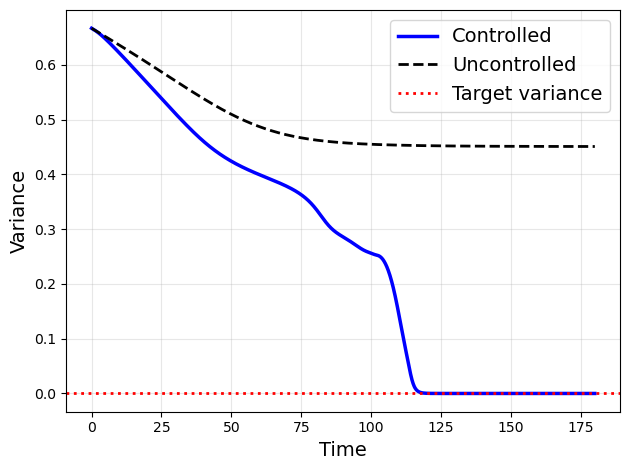

In [30]:
plt.plot(time_vals[:1801], V_traj_anim, 'b-', linewidth=2.5, label='Controlled')
plt.plot(time_vals[:1801], V_uncontrolled, 'k--', linewidth=2.0, label='Uncontrolled')
plt.axhline(V_des, color='r', linestyle=':', linewidth=2, label='Target variance')
plt.xlabel('Time', fontsize=14)
plt.ylabel('Variance', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=14)
plt.tight_layout()
#plt.savefig('variance-var0-reg0.pdf')
plt.show()

Animation will show 40 frames from t=0 to t=175.5
✓ Animation saved as 'just_densityN126_uncontrolled.gif'

🎬 Displaying animation from saved GIF file:


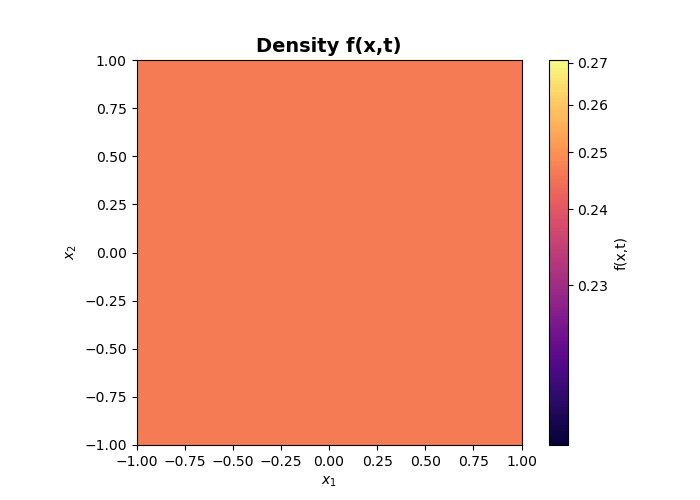

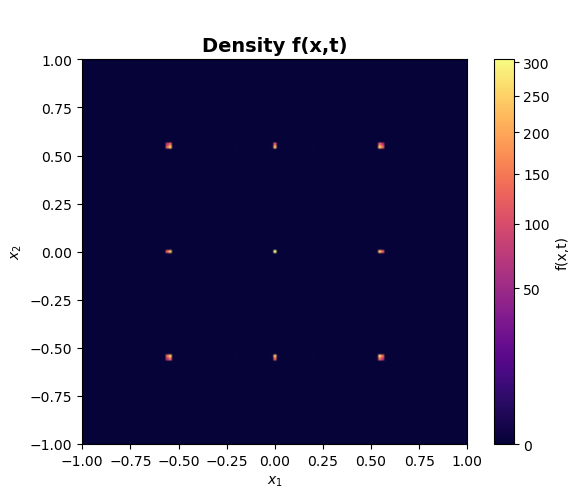

In [31]:
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image
import matplotlib.colors as colors
import os

# Extract time snapshots (every few steps for smoother animation)

time_steps_shortened = 1801
anim_steps = min(40, time_steps_shortened)
step_size = max(1, time_steps_shortened // anim_steps)
time_indices = np.arange(0, time_steps_shortened, step_size)[:anim_steps]
time_vals = np.arange(time_steps_shortened) * dt
time_vals_anim = time_vals[time_indices]

print(f"Animation will show {len(time_indices)} frames from t=0 to t={time_vals_anim[-1]:.1f}")

# Set up the figure for animation
fig_anim, axes_anim = plt.subplots(figsize=(7, 5))

# Top-left: 2D density heatmap
im_anim = axes_anim.imshow(
    init_cond.reshape(N, N).T, extent=[-1, 1, -1, 1],
    origin='lower', cmap='plagma',  norm=colors.PowerNorm(gamma=0.5)
)
axes_anim.set_title('Density f(x,t)', fontsize=14, fontweight='bold')
axes_anim.set_xlabel('$x_1$')
axes_anim.set_ylabel('$x_2$')
cbar = plt.colorbar(im_anim, ax=axes_anim, label='f(x,t)')


# Time text
time_text = fig_anim.suptitle('Time: t = 0.0', fontsize=16, fontweight='bold')

def animate(frame_idx):

    t_idx = time_indices[frame_idx]
    t = time_vals_anim[frame_idx]

    # Update density heatmap
    f_2d = f_uncontrolled[:, t_idx].reshape(N, N).T
    im_anim.set_array(f_2d)
    im_anim.set_clim(vmin = np.min(f_2d), vmax = np.max(f_2d))

    # Update time text
    time_text.set_text(f'Time: t = {t:.1f}')

    return [im_anim, time_text]

# Create animation
anim = FuncAnimation(fig_anim, animate, frames=len(time_indices), interval=500, blit=True)

# Save animation as GIF
gif_filename = 'just_densityN126_uncontrolled.gif'
try:
    anim.save(gif_filename, writer='pillow', fps=4, dpi=100)
    print(f"✓ Animation saved as '{gif_filename}'")
except Exception as e:
    print(f"Could not save GIF: {e}")

# Display animation
if os.path.exists(gif_filename):
    print("\n🎬 Displaying animation from saved GIF file:")
    display(Image(filename=gif_filename))
else:
    print("GIF file not found, trying alternative display methods...")
    try:
        print("Attempting HTML5 display...")
        display(HTML(anim.to_html5_video()))
    except:
        print("HTML5 video failed, trying JS animation...")
        try:
            display(HTML(anim.to_jshtml()))
        except Exception as e:
            print(f"All display methods failed: {e}")
            print("You can view the animation by opening 'density_evolution.gif' in an image viewer")

In [32]:
n1 = 128
n2 = 128
nu = 0
variance_desired = 0
Jhat_p = np.zeros((n1, n2))

I1_grid = np.linspace(0.0, 1.0, n1)
I2_grid = np.linspace(0.0, 1.0, n2)

f_cur_t = f_opt[:, 550].copy()
w_cur_t = w_opt[:, 550].copy()

for i1, I1_val in enumerate(I1_grid):
    for i2, I2_val in enumerate(I2_grid):
        f_all, w_all, fhalf_all = solve_pde_with_w(f_cur_t, w_cur_t, np.array([I1_val,I2_val]), dt, dx, K+1, N, d, x_grid, beta, r1, r2, num_threads=None, progress=False)
        Jhat_p[i1, i2] = instantaneous_objective(np.array([I1_val, I2_val]), f_all, w_all, dt, dx, N, d, x_grid, K*dt, nu, variance_desired)

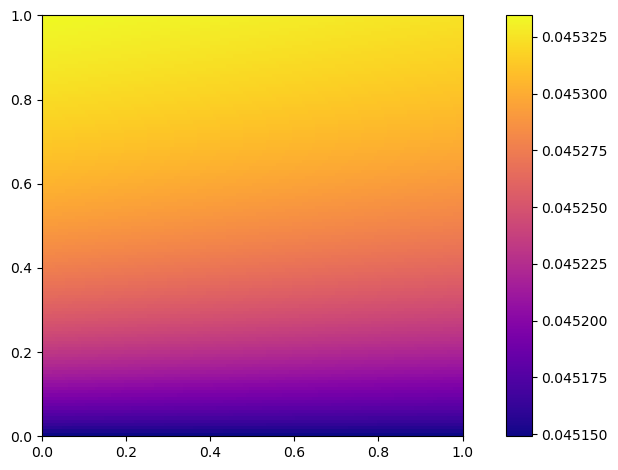

In [34]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
fig, ax = plt.subplots()

im = ax.imshow(
    Jhat_p.T,
    origin='lower',
    extent=[I1_grid[0], I1_grid[-1], I2_grid[0], I2_grid[-1]],
    aspect='auto',
    cmap='plasma'
)
ax.set_box_aspect(1)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.00001)

fig.colorbar(im, cax=cax)
plt.xlabel('$I_1$', fontsize=14)
plt.ylabel('$I_2$', fontsize=14)
plt.tight_layout()
plt.savefig('reduced-cost-var0-reg0-t55-square.pdf')
plt.show()